---
title: "Regression analysis: least squares and regularisation"
short_title: "Regression analysis"
description: "Least squares and linear regression on an example application, categorical regressors with one-hot encoding, and regularisation with ridge and lasso."
---

Once a dataset has been prepared well enough (missing data replaced, suitably rescaled, new features defined), you can venture into a regression analysis. A regression describes the relationship between two variables. One of them is treated as depending on the other, and the dependence is made explicit as a functional relationship – a mathematical map that computes, approximately, the values of the one variable from the values of the other.

An example, before we fix the vocabulary. In the Iris dataset we suspect a relationship between the length and the width of a petal: longer petals ought to be wider as well. We look at the cloud of points and draw a straight line through it – at first entirely by eye.


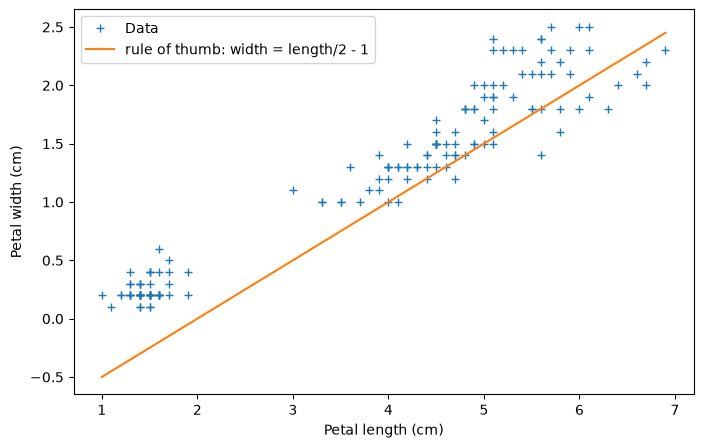

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets

iris_data = datasets.load_iris().data
petal_length, petal_width = iris_data[:, 2], iris_data[:, 3]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(petal_length, petal_width, "+", label="Data")
line = np.linspace(petal_length.min(), petal_length.max(), 2)
ax.plot(line, 0.5 * line - 1, label="rule of thumb: width = length/2 - 1")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend()
plt.show()

What we read off is the rule of thumb

```python
predicted_petal_width = petal_length * 0.5 - 1
```

and with that, the example already contains every ingredient of a regression:

1. There is a **function** that computes the target variable from the explanatory variable – here $x \mapsto 0.5\,x - 1$.
2. The function has **parameters**, here the numbers $0.5$ and $-1$, and we obtained them from the data, not from theory.
3. The prediction is **not exact**. For every single flower something is left over, and we have to keep track of it.

The third point is why a regression is not simply a function. And the second immediately raises the question of whether $0.5$ and $-1$ really are the best numbers – the rest of this chapter answers it. (To anticipate: they are not. The method of least squares finds $0.416$ and $-0.363$ and pushes the mean squared error down from $0.167$ to $0.042$.)

A **regression model** consists of:

* **regressors** $x_i$, that is, a ($k$-variate) 'independent' variable, the *explanatory variable* (here $k$ is the number of regressors, not the number of clusters as in k-means)
* a **regressand** $y_i$, that is, a (univariate) 'dependent' variable, the *target variable*
* **parameters** $\beta_1,\dots,\beta_k$
* **error terms** $\epsilon_i$
* $Y_i = f(X_i, \beta) + \epsilon_i$

For concrete data $(x_i,y_i)$ and a given regression model, $y_i - f(x_i, \beta)$ is also called **the $i$-th residual**.

Some fixed notation will help here. A sample consists of **instances** $x_1,\dots,x_N$ together with the associated values of the target variable $y_1,\dots,y_N$, which in machine learning are called **labels**. If the regressor is multidimensional we write $x_{ij}$ for the value of the $j$-th feature at the $i$-th instance – the first index counts the rows of the table, the second the columns. The model's **prediction** is

$$
y_i^{pred} := f(x_i; \beta),
$$

so it depends on the estimated parameters and changes with them. The residuals are then exactly the differences $y_i - y_i^{pred}$, and so they are all we ever see of the error terms: the error term $\epsilon$ is a random variable we never observe; the residuals are its instances, once we have committed to a $\beta$. That is why you check a regression model by looking at its residuals – they ought to look like a sample from the distribution you assumed for $\epsilon$.

A regression analysis consists of setting up a regression model and then estimating the function $f$ that fits the data best – the one with the smallest residuals.

Particular regression methods differ in the kind of function $f$ they permit.
In linear regression, $f$ is linear in the parameters $\beta$.

```{admonition} Example
For simplicity let $k=1$, that is, let $X_i$ be a univariate variable.
If we choose the class of constant functions for $f$, then $f(X_i,\beta) = \beta_1$
and we are looking for the $\beta_1$ with $Y_i = \beta_1 + \epsilon_i$, that is, a $\beta_1$ that minimises the distance $d(\beta_1, y_i) = y_i - \beta_1$ across all the values $y_i$.
This happens when $\texttt{mse}(y,\beta_1) = \frac{1}{n} \sum_{i=1}^n (y_i - \beta_1)^2$ is minimal, that is, for $\beta_1 = \texttt{mean}(y)$.
```

```{admonition} Example
k-means can be seen as a regression method: the parameters $\beta$ describe the positions of the centroids, and the function $f$ picks the class by the nearest centroid. The k-means method itself is the search for an approximation to the optimal parameters $\beta$.

In k-means the error terms are assumed to be normally distributed and uncorrelated.
```

```{admonition} Example
Every classification method is a regression in which the dependent variable is the class and the regressors are all the data used for the classification. This should not be taken literally, though: a linear regression directly on class numbers $0, 1, 2, \dots$ is not a sensible classifier, because the numbers are not values on a scale. Classification methods such as *logistic regression* therefore interpose a link function that maps the range onto class probabilities.
```

## Least squares

```{admonition} Definition
Minimising the **residual sum of squares** $\sum_{i=1}^N {\left(Y_i - f(X_i,\beta)\right)}^2$ in a regression model yields an estimate for $\beta$ known as the **least squares estimator**.
```

The least squares estimator is a maximum likelihood estimator if the error terms are assumed to be normally distributed (the model for this is at the end of the section *Linear regression*).

```{admonition} Example
If, for points $(x_i,y_i)$ in the plane, we compute a straight line
that minimises the total distance to all the points (a so-called line of best fit),
then this is exactly a regression with $f(x, \beta) = \beta_0 + \beta_1 x$.
The regression equation $Y_i = f(X_i, \beta)$ becomes the equation of a line
$y_i = \beta_0 + \beta_1 x_i$
in which $\beta_0$ is the intercept on the $y$-axis (at $x_i=0$) and $\beta_1$ is the slope of the line.

The least squares method now estimates $\beta_0$ and $\beta_1$ so
that $\sum_{i=1}^N {\left(y_i - \beta_1x_i - \beta_0  \right)}^2$ is minimised.

If $\beta_0=0$, the minimisation problem is one we can solve.
We differentiate with respect to $\beta_1$ and look for zeros:

$$
\begin{aligned}
0 &= \sum_{i=1}^N 2{\left(y_i - \beta_1 x_i  \right)}{\left(- x_i  \right)} \\
  &= \sum_{i=1}^N 2 \left( \beta_1 x_i^2 - y_i x_i \right) \\
  &= 2\left(\beta_1 \sum_{i=1}^N x_i^2 - \sum_{i=1}^N x_iy_i \right)
\end{aligned}
$$

and so $\beta_1 = \dfrac{\sum_{i=1}^N x_iy_i}{\sum_{i=1}^N x_i^2}$.
```

In general, $\beta_0$ can be computed with the formula

$$
\beta_0 = \texttt{mean}(y) - \beta_1\texttt{mean}(x).
$$

So to determine $\beta_1$ first in the general case, you shift the data by their means, replacing $x_i$ by $x_i' = x_i - \texttt{mean}(x)$ and $y_i$ by $y_i' = y_i - \texttt{mean}(y)$. That yields the formula

$$
\beta_1 = \dfrac{\sum_{i=1}^N (x_i - \texttt{mean}(x))(y_i - \texttt{mean}(y))}{\sum_{i=1}^N (x_i - \texttt{mean}(x))^2}
$$

Divide numerator and denominator by $N$ and you are looking at two quantities we already know: on top, the empirical covariance of $x$ and $y$; underneath, the empirical variance of $x$ (both in the $n$-version, see the remark *For data* in the chapter [Covariance](covariance.md)). The slope of the line of best fit is therefore

$$
\beta_1 = \dfrac{\operatorname{Cov}(x,y)}{\sigma^2(x)}, \qquad \beta_0 = \texttt{mean}(y) - \beta_1\,\texttt{mean}(x).
$$

This is the form that is quickest to compute by hand, and it also says something: the slope is the covariance, normalised by the spread of the regressor. Compare it with the correlation coefficient $\rho = \operatorname{Cov}(x,y) / (\sigma(x)\sigma(y))$ from the chapter [Covariance](covariance.md) and you get $\beta_1 = \rho\,\sigma(y)/\sigma(x)$ – correlation and regression slope differ only by the ratio of the two standard deviations.

```{admonition} Example
For the four points $x = (-2, -1, 1, 2)$ and $y = (-3, -1, 1, 3)$ both means are $0$, so

$$
\sigma^2(x) = \tfrac14\left( 4 + 1 + 1 + 4 \right) = 2.5, \qquad
\operatorname{Cov}(x,y) = \tfrac14\left( 6 + 1 + 1 + 6 \right) = 3.5,
$$

and therefore $\beta_1 = 3.5 / 2.5 = 1.4$ and $\beta_0 = 0 - 1.4 \cdot 0 = 0$. The line of best fit is $y = 1.4\,x$.
```


In [2]:
import numpy as np
np.random.seed(1234)

# generate synthetic data:
x = np.linspace(-2, 8)
y = x**2 + 3*x - 7 + np.random.uniform(-3, 3, size=x.shape)

# compute estimate from before:
x_centered = x - np.mean(x)
y_centered = y - np.mean(y)
beta_1 = ( x_centered.T @ y_centered ) / sum(np.square(x_centered))
beta_0 = np.mean(y) - beta_1*np.mean(x)
# the same number as covariance over variance (ddof=0: the n-version, as in np.var):
assert np.isclose(beta_1, np.cov(x, y, ddof=0)[0, 1] / np.var(x))
print("line equation is y = %f*x + %f" % (beta_1, beta_0))


line equation is y = 8.912806*x + -6.929693


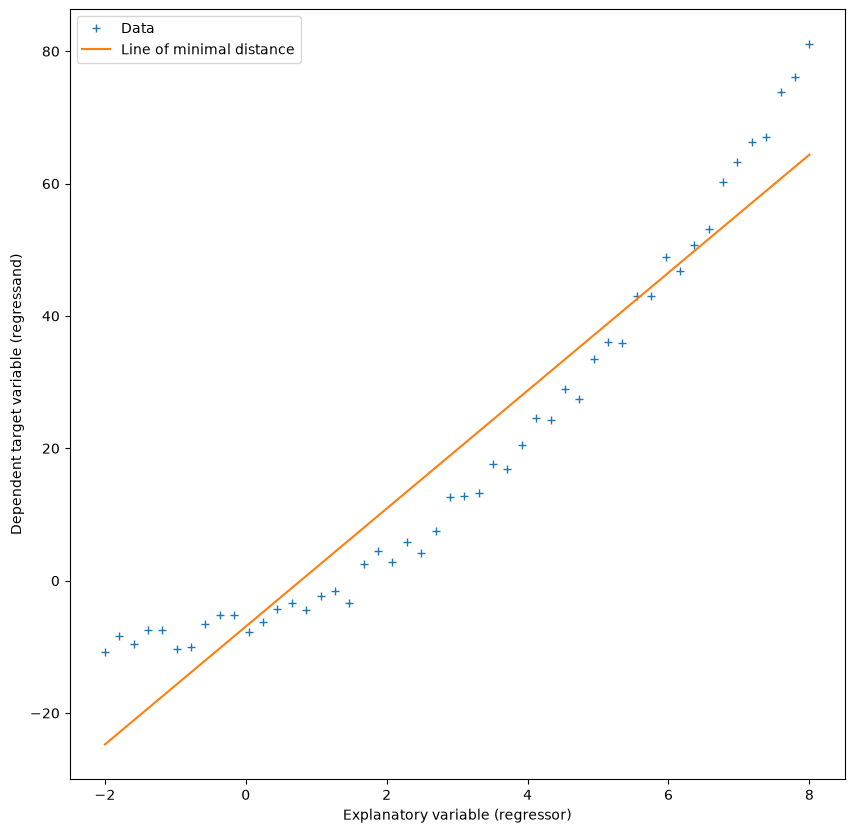

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Data")
ax.plot(x, beta_0 + x*beta_1, label="Line of minimal distance")
ax.set_xlabel("Explanatory variable (regressor)")
ax.set_ylabel("Dependent target variable (regressand)")
ax.legend()
plt.show()

The method of least squares can also be run directly in Scipy (so there is no need to remember the formulas or the derivation):

In [4]:
from scipy.optimize import curve_fit

# define function class for regression (linear):
def f(x, beta_0, beta_1):
    return beta_1*x + beta_0

# perform regression analysis:
parameters, covariance_matrix = curve_fit(f, x, y)
assert np.all(np.isclose((beta_0, beta_1), parameters))

From the Scipy documentation:

`scipy.optimize.curve_fit`
>
> Use non-linear least squares to fit a function, f, to data.
>
> Assumes ydata = f(xdata, *params) + eps.

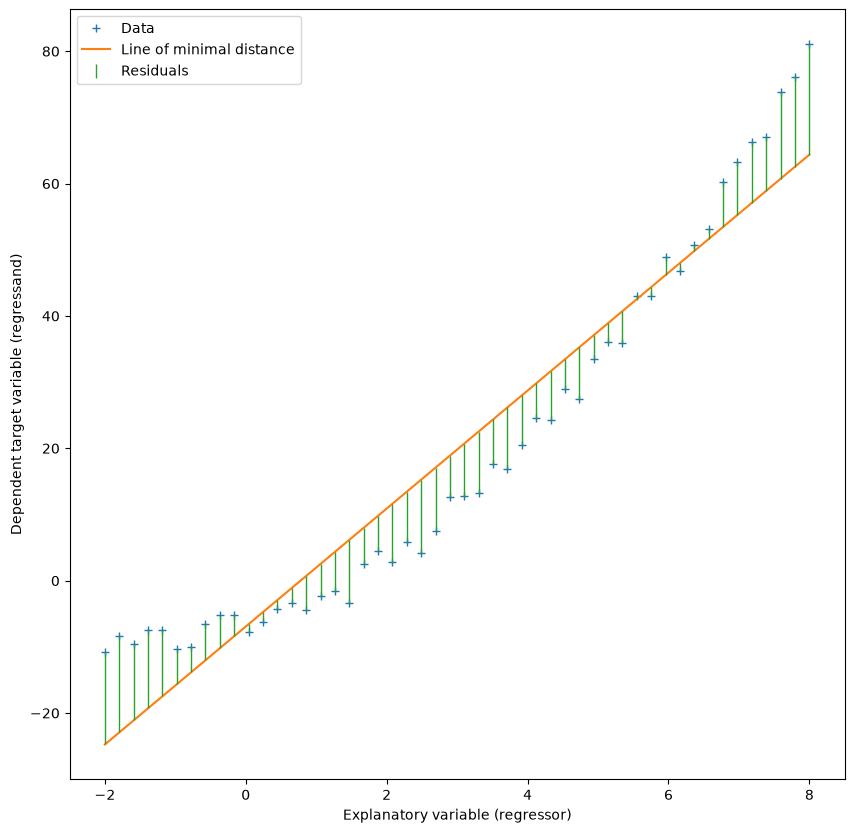

In [5]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Data")
ax.plot(x, f(x, beta_0, beta_1), label="Line of minimal distance")
yerr = np.stack((np.maximum(np.zeros_like(y), y - f(x, beta_0, beta_1)),
                 -np.minimum(np.zeros_like(y), y - f(x, beta_0, beta_1))))
ax.errorbar(x, y,
            yerr=yerr,
            linewidth=0, elinewidth=1,
            label="Residuals")
ax.set_xlabel("Explanatory variable (regressor)")
ax.set_ylabel("Dependent target variable (regressand)")
ax.legend()
plt.show()

Note that this is not the direction of maximal variance – that too minimises distances, but the distances of the data points $(x,y)$ to the line. Linear regression minimises not the distances of the data points to the line but the residuals, which are the distances along the $y$-axis. The plot above shows this: the green bars run parallel to the $y$-axis, not perpendicular to the line (which is what the distance to the line would be).

This also makes clear that regression is an asymmetric method: regressor and regressand cannot be swapped without changing the model. When searching for the line along the direction of maximal variance, by contrast, the $x$- and $y$-coordinates are on an equal footing and the solution is invariant under rotations.

## Linear regression

```{admonition} Definition
A regression of the form $Y_i = f(X_i, w) + \epsilon_i$ with $f(x, w) = w^T x$ is called a **linear regression**. The entries of the vector $w$ are called the **weights** of the model: $w_j$ says how strongly the regressor $X_j$ enters the prediction.
```

```{admonition} Definition
A regression of the form $Y_i = f(X_i, w, w_0) + \epsilon_i$ with

$$f(x, w, w_0) = w^T x + w_0$$

is called a **linear regression with bias** $w_0$.
```

The second definition looks more general, but it reduces to the first. Append a constant one to the regressors and the bias to the weights:

$$
X_+ := (1, X_1, \dots, X_k), \qquad w_+ := (w_0, w_1, \dots, w_k), \qquad (w_+)^T X_+ = w^T X + w_0.
$$

This is the usual tacit convention: for $x = (a,b)$ we then have $f(x,w) = w^T x = (w_0,w_1,w_2)\cdot(1,a,b) = w_0 + w_1 a + w_2 b$. The $w_0$ term (denoted $\beta_0$ earlier) is also called the **bias term** (intercept). It has nothing to do with the bias of an estimator from the previous chapter; the word simply has two meanings in the machine learning literature.

```{admonition} Note
An example of such a model with a bias: the price $Y$ of a house is to be predicted from the distance to the city centre $X_1$ and the age $X_2$,

$$
Y = \beta_1 X_1 + \beta_2 X_2 + \beta_0 + \epsilon.
$$

This is exactly the model we work through on the Melbourne dataset further down.

A word on terminology: in computer science and machine learning the function $f(x_1,x_2) = \beta_1 x_1 + \beta_2 x_2 + \beta_0$ is called "linear", although in the sense of linear algebra it is not – only $(x_1,x_2) \mapsto \beta_1 x_1 + \beta_2 x_2$ is linear, since a linear map sends zero to zero. In mathematics $f$ is called an *affine linear* function. The $X_+$ trick above is exactly the translation between the two usages: the affine linear function on $\mathbb{R}^k$ is a linear function on $\mathbb{R}^{k+1}$.
```


A simple linear regression can be carried out with Scipy.stats:

In [6]:
from scipy.stats import linregress

linregress_result = linregress(x, y)
slope, intercept, r, p, se = linregress_result
print("Slope: %f" % slope)
assert np.isclose(slope, beta_1)
print("Intercept: %f" % intercept)
assert np.isclose(intercept, beta_0)
print("Correlation coefficient: %f" % r)
print("p-value: %.32f" % p)
print("Standard error of the slope: %f" % se)

Slope: 8.912806
Intercept: -6.929693
Correlation coefficient: 0.959514
p-value: 0.00000000000000000000000000046030
Standard error of the slope: 0.377630


The five return values are worth a moment. `slope` is the slope $\beta_1$ and `intercept` is the intercept $\beta_0$, that is, the bias – those are the two parameters we were after. `r` is the correlation coefficient between $x$ and $y$ (see [Covariance and dependence](covariance.md)); its square $r^2$ is the proportion of the variance of $y$ that the model explains, and it turns up again further down as the coefficient of determination $R^2$. `p` belongs to a test that Scipy ran along the way, unasked (more on that in a moment). And `se`, despite the name, is not a squared error but the **standard error of the slope estimate**: the estimated standard deviation of `slope` if you were to repeat the whole experiment with a fresh sample. As a rule of thumb, the true slope lies within `slope` $\pm\ 2 \cdot$ `se` with a probability of about $95\,\%$.

Scipy has also run a test for us straight away: a two-sided test with the null hypothesis that the slope `slope` equals $0$. Since the $p$-value is considerably smaller than $\alpha = 0.05$, we reject the hypothesis and assume a slope $\neq 0$. (For now we simply take this as given, without going further into statistical tests – or we ignore this part of the Scipy.stats output.)

Before we write this down in general, here is an example in which the trick is immediately obvious. The Iris dataset gives us the petal length $X_1$ and the petal width $X_2$, and we would like to predict the sepal length $Y$. Now $Y$ presumably depends less on length or width individually than on the *area* of the petal – and that, up to a shape factor, is the product of the two. So we build a new regressor $X_3 := X_1 X_2$ and use it to compute a perfectly ordinary linear regression $Y = w_1 X_3 + w_0 + \epsilon$.

Slope: 0.150646
Intercept: 4.970482
Correlation coefficient: 0.857300
Standard error of the slope: 0.007436


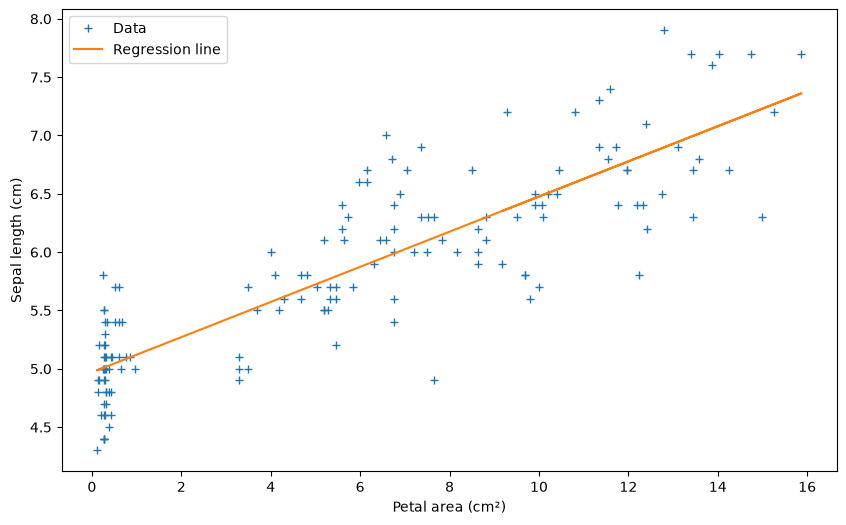

In [7]:
from sklearn import datasets

iris = datasets.load_iris()
x_iris = iris.data
petal_area = x_iris[:, 2] * x_iris[:, 3]   # petal length times petal width
sepal_length = x_iris[:, 0]

result = linregress(petal_area, sepal_length)
print("Slope: %f" % result.slope)
print("Intercept: %f" % result.intercept)
print("Correlation coefficient: %f" % result.rvalue)
print("Standard error of the slope: %f" % result.stderr)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(petal_area, sepal_length, "+", label="Data")
ax.plot(petal_area, result.intercept + result.slope * petal_area, label="Regression line")
ax.set_xlabel("Petal area (cm²)")
ax.set_ylabel("Sepal length (cm)")
ax.legend()
plt.show()

All we have done here is apply the function $\phi(X_1, X_2) := X_1 X_2$ to the regressors before the regression. The model stays linear – in the weights $w$, and that is what counts.

For comparison: the petal length alone gives $r = 0.872$, a little more than the area does. A basis function expansion is not automatically the better regressor just because it is more complicated – it is a hypothesis about the data, and whether it helps is an empirical question. Such preprocessing steps have a name of their own.

```{admonition} Definition
If a regressor variable has the form $\phi(X_i)$, where $\phi$ is an arbitrary function with a suitable domain, then this is still called a **linear regression with regressor $X_i$ and basis function expansion**.
```

So in a linear regression only one thing is linear: the function $f$, in the variables $w$. This also lets us read the earlier tacit replacement of $x$ by $(1,x)$ as a basis function expansion, with $\phi(x) = (1,x)$.

Since a linear regression analysis is very easy to carry out, the central question in linear regression becomes how to set up the model – and in particular the basis function – from the data.

The case $w = (w_0, w_1)$ is called a **simple linear regression**, the more general case a **multiple linear regression**, because there the regressor is a multivariate independent variable $X$. Scipy.stats's linear regression can only do the simple kind!

So we now turn to multiple linear regression with scikit-learn:

```{admonition} Caution: these terms elsewhere
:class: warning
Outside this chapter, its words are often used more narrowly than we have defined them here. Three narrowings you will meet regularly:

1. **Regression vs. classification.** For us, classification is a special case of regression (the target variable is then simply categorical). The widespread usage, by contrast, is "regression = continuous target variable, classification = discrete target variable", and libraries are mostly organised along those lines – in scikit-learn, `LinearRegression` and `LogisticRegression` sit in different corners of the documentation, although both are regressions in the sense used here.
2. **Regression = linear regression.** For us, a regression is any model with a function $f$. Someone who says "regression" without a qualifier, though, often means the linear one.
3. **Regression = regression line.** Regression works in arbitrarily many dimensions; what is meant, though, is often the one-dimensional case, whose result can be drawn as a straight line.

None of these narrowings is wrong; you only have to know which meaning the word is carrying at the moment. When in doubt, ask: what is the target variable, and how many regressors are there?
```

In [8]:
from sklearn.linear_model import LinearRegression

# first look at linear, to compare with the above:
linear_regressor = LinearRegression()
linear_regressor.fit(x.reshape(-1, 1), y)
Y_pred = linear_regressor.predict(x.reshape(-1, 1))

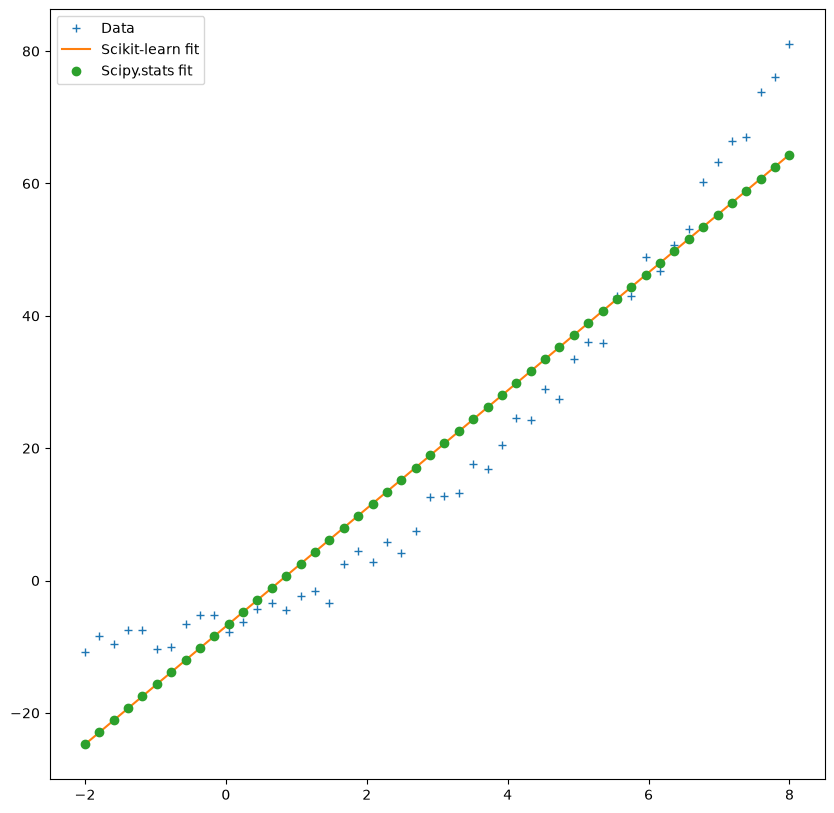

In [9]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Data")
ax.plot(x, Y_pred, label="Scikit-learn fit")
ax.plot(x, f(x, beta_0, beta_1), "o", label="Scipy.stats fit")
ax.legend()
plt.show()

From the scikit-learn documentation:

`sklearn.linear_model.LinearRegression`
>
> From the implementation point of view, this is just plain Ordinary Least Squares (scipy.linalg.lstsq) or Non Negative Least Squares (scipy.optimize.nnls) wrapped as a predictor object.

Seen this way, scikit-learn is not 'better' than Scipy, just a layer on top of it.

```{admonition} Example
Using the basis function $\phi(x) = (1,x,x^2,x^3,\dots,x^d)$ with $d > 0$ is called **polynomial regression**.
Concretely, for $d=2$ this means $f(x,w) = w_0 + w_1x + w_2x^2$. Once again it is plain to see: $f$ is linear in $w$, not in $x$.
```

One problem in choosing a basis function for a regression model is overfitting. With too many parameters available, the data can certainly be fitted very well, but the model does not generalise well. In practice this is checked by fitting on a training dataset and then evaluating on a test dataset.

```{admonition} Example
We look at overfitting as a function of the parameter $d$ of the polynomial regression, on the same dataset as in the earlier example with a regression line (the case $d=1$).
```

In [10]:
# define basis function class
def phi(x, d):
    return np.dstack([np.power(x, i) for i in range(d+1)]).squeeze()

def plot_regression(x, y, Y_pred, ax, x_test=None, y_test=None):
    ax.plot(x, y, "+", label="Data")
    if(x_test is None):
        x_test = x
    ax.plot(x_test, Y_pred, label="Model")
    if(y_test is None):
        y_test = y
    yerr = np.stack(( np.maximum(np.zeros_like(y_test), y_test - Y_pred),
                     -np.minimum(np.zeros_like(y_test), y_test - Y_pred)))
    ax.errorbar(x_test, y_test,
                yerr=yerr,
                linewidth=0, elinewidth=1,
                label="Residuals")
    ax.set_xlabel("Explanatory variable (regressor)")
    ax.set_ylabel("Dependent target variable (regressand)")
    ax.legend()
    return ax

def poly_regression_plot(x, y, d):
    # perform regression analysis:
    transformed_x = phi(x, d)

    linear_regressor = LinearRegression()
    linear_regressor.fit(transformed_x, y)
    Y_pred = linear_regressor.predict(transformed_x)

    fig, ax = plt.subplots(figsize=(10,10))
    plot_regression(x, y, Y_pred, ax).\
      set_title("Polynomial regression of degree %d" % d)
    plt.show()

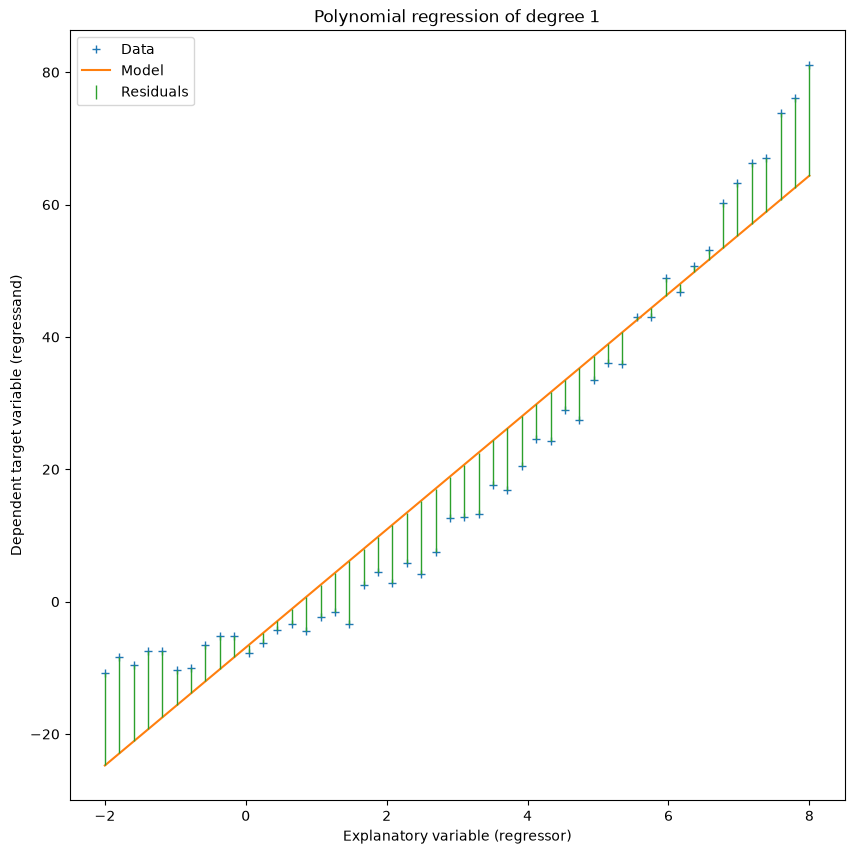

In [11]:
poly_regression_plot(x, y, 1)

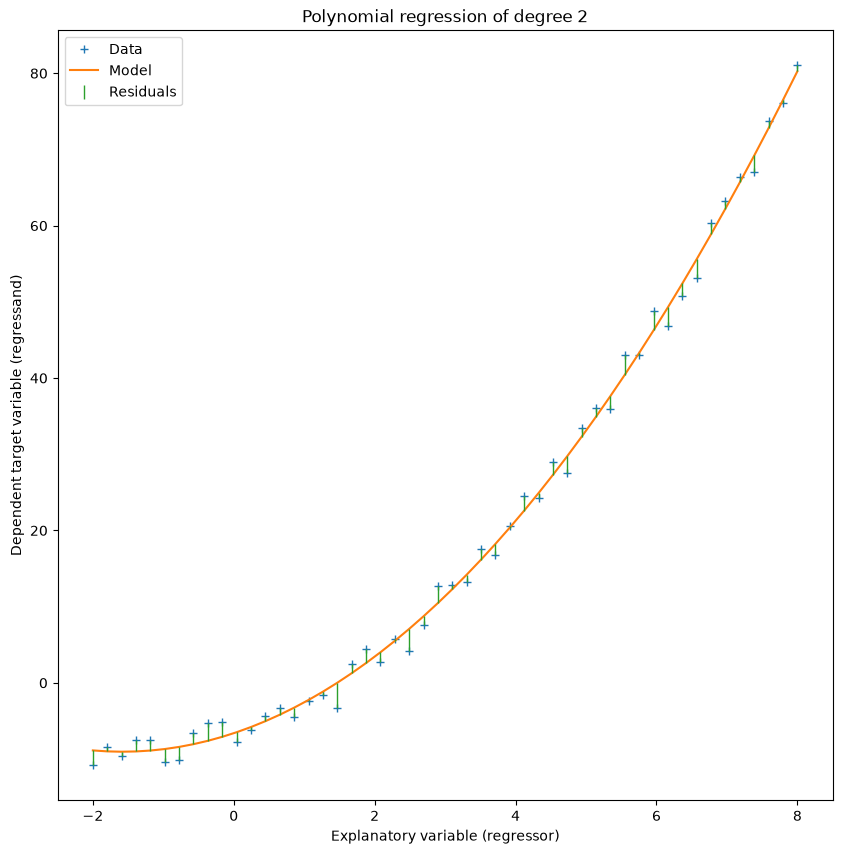

In [12]:
poly_regression_plot(x, y, 2)

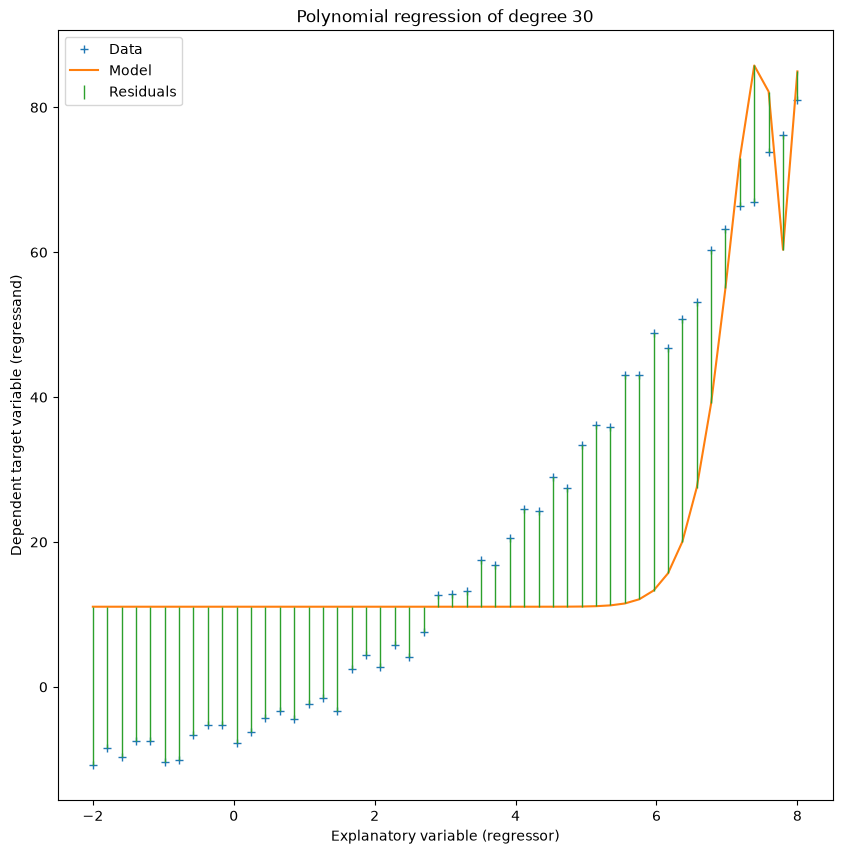

In [13]:
poly_regression_plot(x, y, 30)

A linear regression model can also be formulated as

$$
P(y|X, \theta) = \mathcal{N}(w^T X, \sigma^2)
$$

or, with a basis function expansion,

$$
P(y|X, \theta) = \mathcal{N}(w^T \phi(X), \sigma^2)
$$

Here the $\theta_i$ are the parameters of the normally distributed errors $\epsilon_i$.

## An example application

We look at the [Melbourne Housing Market dataset by Anthony Pino](https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market). It is licensed CC BY-NC-SA 4.0 and is therefore exempt from the licence of these notes: re-use only non-commercially and under the same terms.

To get started, we clean the data a little.

In [14]:
import pandas as pd

df = pd.read_csv("Melbourne_housing_FULL.csv")
print(df.shape)
print(df.columns)

(34857, 21)
Index(['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG',
       'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude',
       'Longtitude', 'Regionname', 'Propertycount'],
      dtype='str')


In [15]:
# don't care about lat, lon here:
df = df.drop(columns=['Lattitude','Longtitude'])

# make Date a date:
df['Date'] = pd.to_datetime(df['Date'], format="%d/%m/%Y")

# Postcode is not really numeric:
df['Postcode'] = df['Postcode'].astype('category')

# make string variables categorical:
string_columns = df.select_dtypes(include=['object', 'string']).columns  # 'string' for pandas >= 3
df[string_columns] = df[string_columns].astype('category')

# Transform year built to age:
df['Age'] = 2017 - df['YearBuilt']
df = df.drop(columns='YearBuilt')

# kill faulty data:
df = df[df['BuildingArea'] != 0]
df = df[df['Age'] < 500]

# remove all suspects with missing data
df = df.dropna()

# remaining numerical variables:
numerical_columns = df.select_dtypes(['float']).columns
print(numerical_columns)

Index(['Price', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize',
       'BuildingArea', 'Propertycount', 'Age'],
      dtype='str')


In [16]:
regressor_columns = numerical_columns.drop('Price')
x = df[regressor_columns]
y = df['Price']

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test \
 = train_test_split(x, y, test_size = .20, random_state=0)

regressor = LinearRegression()
regressor.fit(x_train, y_train)
y_pred = regressor.predict(x_test)

from sklearn.metrics import r2_score
print("R^2 = %f%% of the variance is explained by the linear model"
      % (100*r2_score(y_test, y_pred)))

R^2 = 50.355458% of the variance is explained by the linear model


Before we interpret the coefficients, we check the model assumption that the error terms $\epsilon_i$ scatter around $0$ independently of $x$: the residuals $y_i - f(x_i, \beta)$, plotted against the prediction, ought to lie around $0$ with no discernible pattern. A funnel means that the spread depends on the price; curvature, that a linear relationship is not enough.

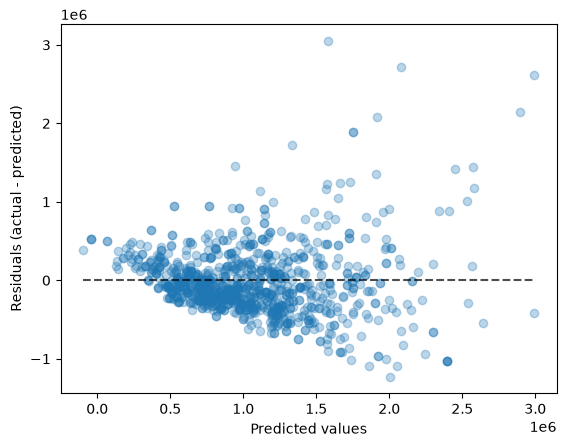

In [17]:
from sklearn.metrics import PredictionErrorDisplay

PredictionErrorDisplay.from_predictions(y_test, y_pred, kind="residual_vs_predicted",
                                        scatter_kwargs={"alpha": 0.3})
plt.show()

```{admonition} Definition
$$
R^2 = 1 - \dfrac{\sum_{i=1}^N {\left( y_i - f(x_i,\beta) \right)}^2}{\sum_{i=1}^N {\left( y_i - \texttt{mean}(y) \right)}^2}
$$

The quantity $R^2$ is also called the **coefficient of determination**. The numerator is the residual sum of squares of the model, the denominator that of the best constant model $\texttt{mean}(y)$; so $R^2$ measures what proportion of the spread of $y$ the model explains away, compared with the constant. For least squares with an intercept this equals, on the training data, $\sum (f(x_i,\beta) - \texttt{mean}(y))^2 / \sum (y_i - \texttt{mean}(y))^2$, the proportion of "explained" variance; on test data, as above, only the first form holds, and there $R^2$ can even come out negative (chapter [Model selection](model-selection.ipynb)).
```

In [18]:
cdf = pd.DataFrame(data = regressor.coef_,
                   index = regressor_columns,
                   columns = ['Coefficients'])
cdf

,Coefficients
Distance,-27377.550245
Bedroom2,109775.843441
Bathroom,264198.517970
Car,55837.834214
Landsize,23.997980
BuildingArea,2238.496526
Propertycount,-0.688488
Age,6081.670366


Interpretation:

If one house is a year older than another, the associated price difference is about $6081$ (Australian) dollars. If one house is a kilometre closer to the centre (which Melbourne calls the *CBD*) – that is, its Distance variable is smaller by $1$ – the associated price difference is about $27377$ dollars.

### Categorical regressors: one-hot encoding

While cleaning the data we turned every text column into a `category` – and then quietly
left them out of the model, since `numerical_columns` holds only the `float` columns. Yet
`Type` (h = house, u = unit, that is a flat, t = townhouse) ought to have something to say about the price.

Simply setting $h = 1$, $u = 2$, $t = 3$ would be wrong: `Type` is on a nominal scale, with no order
and no equal spacings, and the regression would compute with both (see
[Descriptive statistics](descriptive-statistics.md), section Level of measurement). Instead, every
level gets a $0/1$ column of its own, the **one-hot encoding**; pandas calls the columns *dummies*.
One of the columns is left out (`drop_first=True`): whatever is neither `u` nor `t` is `h`, and the
omitted level becomes the *reference category* against which the other coefficients are measured.
If all three columns were kept, their sum would always be $1$ – the same information as the
intercept $\beta_0$ – and the parameters would no longer be uniquely determined (the *dummy variable trap*).


In [19]:
dummies = pd.get_dummies(df['Type'], prefix='Type', drop_first=True, dtype=float)
print(dummies.head())

x_onehot = pd.concat([df[regressor_columns], dummies], axis=1)
x_train_oh, x_test_oh, y_train_oh, y_test_oh \
 = train_test_split(x_onehot, y, test_size=.20, random_state=0)

regressor_onehot = LinearRegression().fit(x_train_oh, y_train_oh)
print("R^2 without Type: %.1f%%" % (100 * r2_score(y_test, y_pred)))
print("R^2 with Type:    %.1f%%" % (100 * r2_score(y_test_oh, regressor_onehot.predict(x_test_oh))))

pd.DataFrame(data=regressor_onehot.coef_, index=x_onehot.columns, columns=['Coefficients']).tail(2)


    Type_t  Type_u
2      0.0     0.0
4      0.0     0.0
6      0.0     0.0
11     0.0     0.0
14     0.0     0.0
R^2 without Type: 50.4%
R^2 with Type:    50.7%


,Coefficients
Type_t,-66617.632753
Type_u,-178403.074899


The two new coefficients read as a price difference *relative to a house* with otherwise equal
features: in the model, a flat with the same area, the same age and the same distance to the
centre is around $178\,000$ dollars cheaper, a townhouse around $67\,000$ dollars.
That $R^2$ barely rises is, on reflection, no surprise: most of what
`Type` reveals about the price already sits in `BuildingArea`, `Landsize` and `Bedroom2` – flats
are, above all, smaller. So the encoding did not invent the feature's value; it only made
it readable.

An ordinal feature (a condition "poor / medium / good", say) could, by contrast, fairly have been
encoded as $1, 2, 3$ – there the order is real, and only the equal spacings are an assumption. For
nominal features with very many levels (`Suburb`, say, with several hundred suburbs)
one-hot encoding becomes unwieldily wide; then other ideas are needed, which go beyond this
course.

To close this example application, two more pictures of linear regression in the variables distance and age – first one of them, then both:


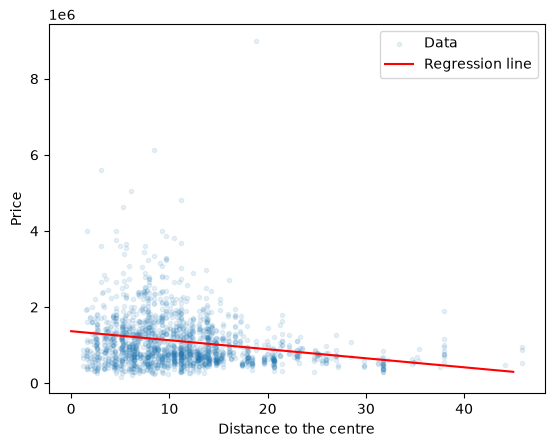

In [20]:
regressor_variable = x_train[["Distance"]]
regressor.fit(regressor_variable, y_train)
y_pred = regressor.predict(regressor_variable)

fig, ax = plt.subplots()
ax.scatter(x_test["Distance"], y_test,
           marker='.', alpha=0.1,
           label="Data")
xs = np.arange(np.max(x_test["Distance"]))
ys = regressor.coef_[0]*xs + regressor.intercept_
ax.plot(xs, ys, color='red', label="Regression line")
ax.set_xlabel("Distance to the centre")
ax.set_ylabel("Price")
ax.legend()
plt.show()

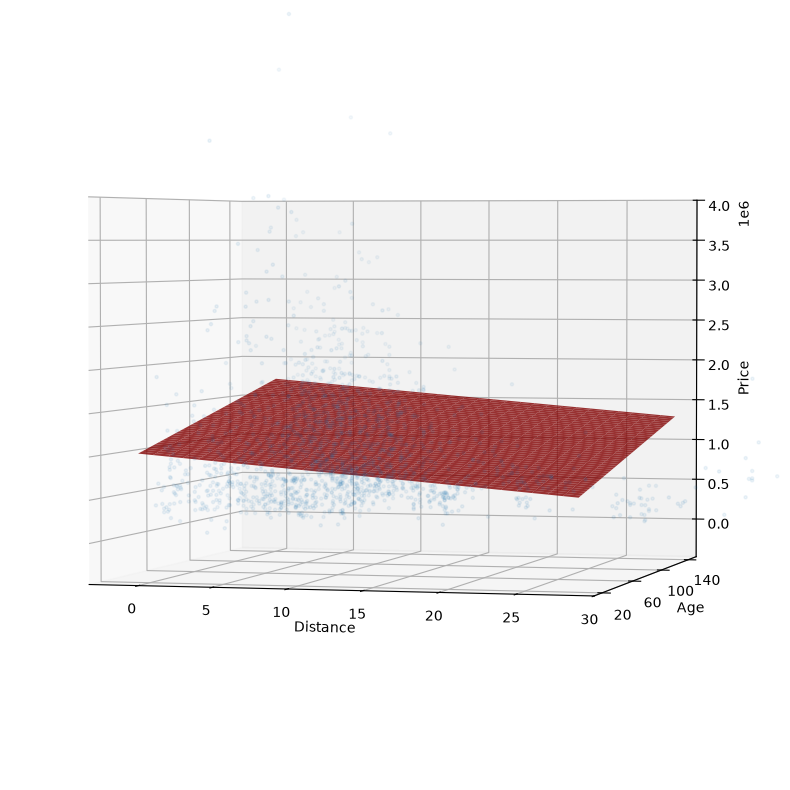

In [21]:
regressor_variable = x_train[["Distance", "Age"]]
regressor.fit(regressor_variable, y_train)
y_pred = regressor.predict(regressor_variable)

from mpl_toolkits.mplot3d import Axes3D

xs = np.arange(30)
ys = np.arange(10, np.max(x_test["Age"]))
xs, ys = np.meshgrid(xs, ys)
zs =   xs*regressor.coef_[0] \
     + ys*regressor.coef_[1] \
     + regressor.intercept_

fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111,projection='3d')
ax.plot_surface(xs, ys, zs,
                alpha=0.8, color='red')
ax.scatter(x_test["Distance"], x_test["Age"], y_test,
           marker='.', alpha=0.3)
ax.set_zlim3d(zmax=4000000)
ax.set_xlim3d(xmax=30)
ax.set_ylim3d(ymin=10)
ax.set_xlabel("Distance")
ax.set_ylabel("Age")
ax.set_zlabel("Price")
ax.set_yticks([20,60,100,140])
ax.view_init(elev=2., azim=-75)
plt.show()

Given how these data look, a polynomial regression would help here as well. We put together a pipeline to compute it.

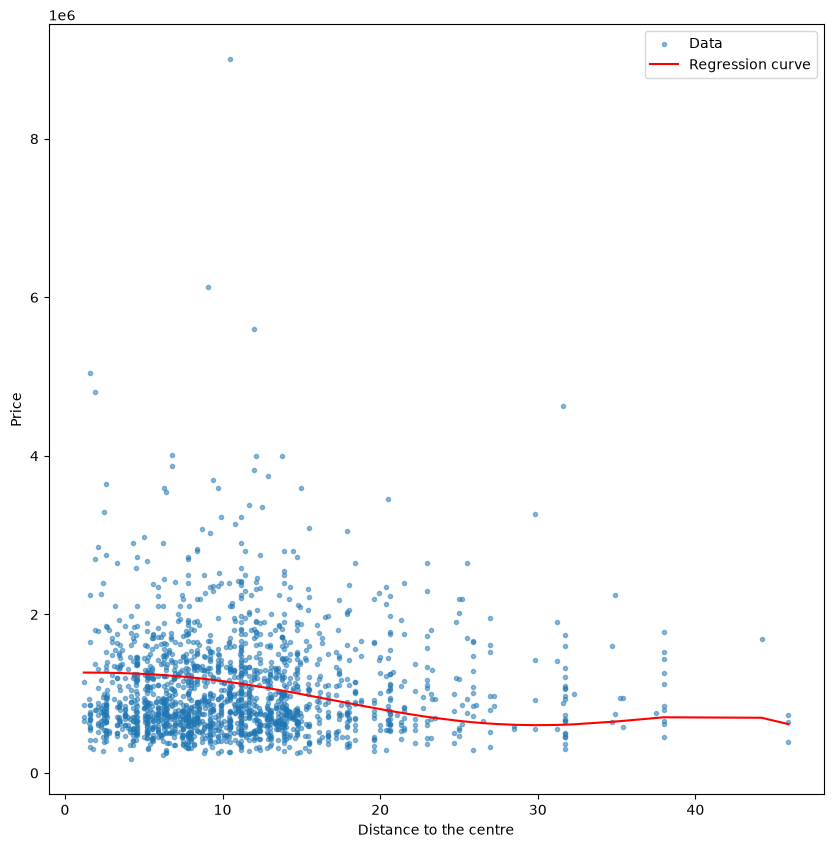

In [22]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

degree = 5

polyreg = make_pipeline(PolynomialFeatures(degree), LinearRegression())
polyreg.fit(x_train[["Distance"]], y_train)
# for plotting purposes, sort:
x_test = x_test.sort_values("Distance")
y_pred = polyreg.predict(x_test[["Distance"]])

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(x_test["Distance"], y_test,
           marker='.', alpha=0.5,
           label="Data")
ax.plot(x_test["Distance"], y_pred,
        color='red', label="Regression curve")
ax.set_xlabel("Distance to the centre")
ax.set_ylabel("Price")
ax.legend()
plt.show()

## Regularisation

With only a few support points in the training data, overfitting becomes all the more likely. We look at this in a few examples:

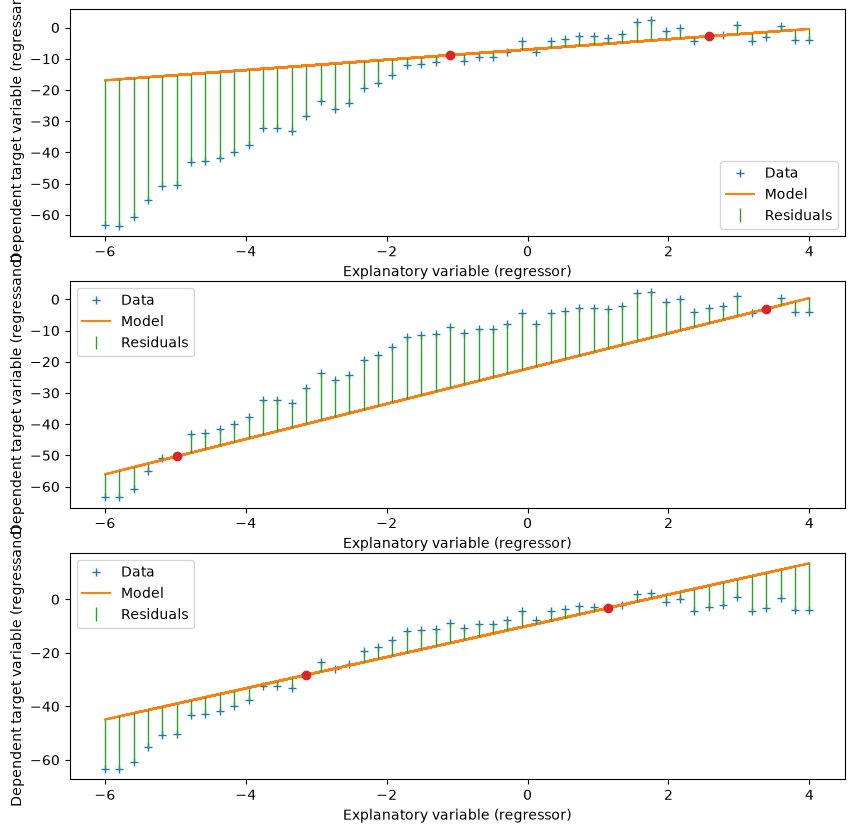

In [23]:
# generate new synthetic data:
np.random.seed(123)
x = np.linspace(-6, 4)
y = -x**2 + 4*x - 5 + np.random.uniform(-4, 4, size=x.shape)

def plot_from_small_training(ax, random_state, model=LinearRegression()):
    # simulate having very few training data:
    x_train, x_test, y_train, y_test \
     = train_test_split(x, y, test_size = .95,
                        random_state=random_state)

    regressor = model
    regressor.fit(x_train.reshape(-1, 1), y_train)
    y_pred = regressor.predict(x_test.reshape(-1, 1))

    plot_regression(x, y, y_pred, ax, x_test, y_test)
    ax.plot(x_train, y_train, "o")

fig, axs = plt.subplots(3, 1, figsize=(10,10))
plot_from_small_training(axs[0], 3)
plot_from_small_training(axs[1], 4)
plot_from_small_training(axs[2], 5)
plt.show()

The trick of regularisation is not to fit the training data *too* well.

**L2 regularisation**, also known as **ridge regression**, minimises a penalty term $P = \alpha \sum_{i=1}^n \beta_i^2$ as an additional optimisation objective while searching for the best fit to the regression problem.
Here $\alpha$ is a free parameter that sets the strength of the penalty.

The name L2 comes from $P$ being the square of the L2 norm.

The same idea of penalising large model weights goes by the name *weight decay* in deep learning (the course *Introduction to Deep Learning*).

There is also **L1 regularisation**, which uses the summand $|\beta_i|$ instead of $\beta_i^2$ and so corresponds to the L1 norm; it is also known as **lasso regularisation**.

![L1 and L2 balls, image by Wikipedia User Nicoguaro, CC BY 4.0](images/L1_and_L2_balls.svg.png)

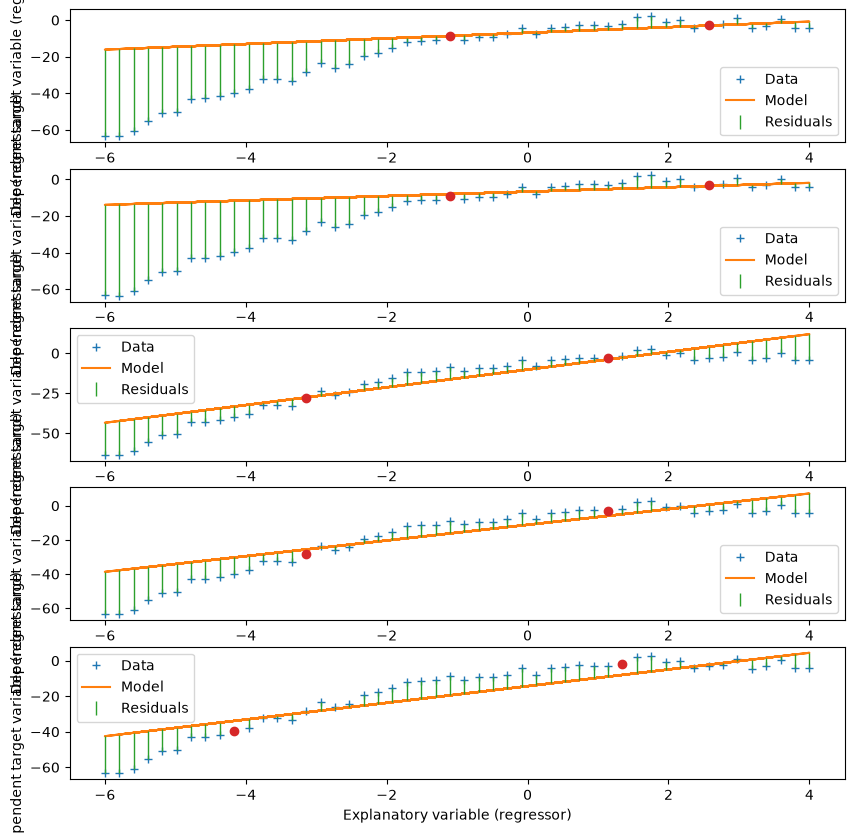

In [24]:
from sklearn.linear_model import Ridge

fig, axs = plt.subplots(5, 1, figsize=(10,10))
plot_from_small_training(axs[0], 3, model=Ridge(alpha=0.5))
plot_from_small_training(axs[1], 3, model=Ridge(alpha=2.5))
plot_from_small_training(axs[2], 5, model=Ridge(alpha=0.5))
plot_from_small_training(axs[3], 5, model=Ridge(alpha=2.5))
plot_from_small_training(axs[4], 10, model=Ridge(alpha=7))
plt.show()

The practical difference between L1 and L2: the L1 penalty sets coefficients to *exactly* $0$ (those are the vertices of the L1 ball in the figure), so it selects regressors. With the polynomial terms $x, x^2, \dots, x^8$ as regressors for the synthetic data above, you can see this directly:

In [25]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

def poly_fit(model):
    pipe = make_pipeline(PolynomialFeatures(degree=8, include_bias=False),
                         StandardScaler(), model)
    return pipe.fit(x.reshape(-1, 1), y)[-1]   # the fitted model at the end of the pipeline

np.set_printoptions(precision=2, suppress=True)
ridge = poly_fit(Ridge(alpha=1.0))
lasso = poly_fit(Lasso(alpha=0.5))
print("Ridge coefficients:", ridge.coef_)
print("Lasso coefficients:", lasso.coef_)
print("Exactly 0 under Lasso:", np.sum(lasso.coef_ == 0), "of", len(lasso.coef_), "coefficients")

Ridge coefficients: [10.6  -7.56  2.39 -1.92 -0.35  0.04 -0.72  0.36]
Lasso coefficients: [11.34 -8.76  0.71 -0.    0.   -0.    0.   -0.  ]
Exactly 0 under Lasso: 5 of 8 coefficients


## Summary

A regression is a model $Y = f(X,\beta) + \epsilon$; *linear* means linear in the parameters, which is why basis functions and one-hot columns do not take us out of the model. The method of least squares yields $\beta_1 = \operatorname{Cov}(x,y)/\sigma^2(x)$, and it is maximum likelihood when the error terms are normally distributed; residual plots check that assumption. Regularisation (ridge, lasso) penalises large coefficients and is the remedy for overfitting when there are too many basis functions.

Video: [Crash Course Statistics Regression](https://www.youtube.com/watch?v=WWqE7YHR4Jc)